# Exercise 61 – A trainable message-passing layer

**Week 12 · Graphs and message passing**

Six small graphs have all node attributes equal to 1. The target for each
node is its number of neighbours (the last graph is held out for testing and
has no targets). We compare three message-passing layers:

| layer | update rule |
|---|---|
| no parameters | $x_i' = \sum_{j \in N(i)} x_j$ |
| $\psi$ | $x_i' = \sum_{j \in N(i)} \psi(x_j)$ |
| $\phi\psi$ | $x_i' = \phi\big(x_i \,\Vert\, \sum_{j \in N(i)} \psi(x_j)\big)$ |

with $\psi$, $\phi$ linear layers. The edge lists include self loops, so the
sum runs over the node itself as well.

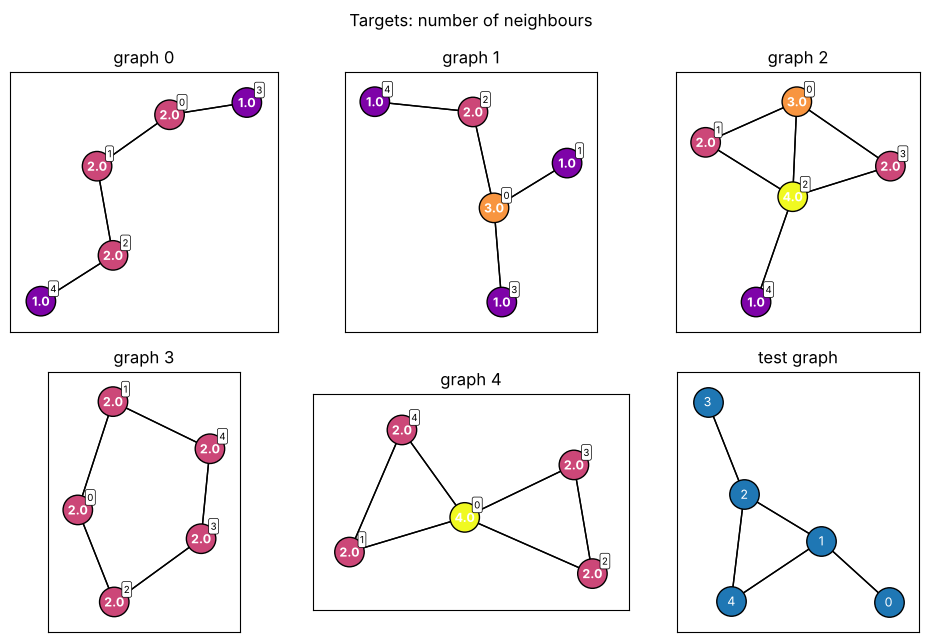

In [1]:
import copy

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import MessagePassing

from comphy.graphs import NeighbourAggregation, PhiPsiConv, plot_graph
from comphy.training import train

torch.manual_seed(0)


def make_graph(edges, pos, y):
    return Data(edge_index=torch.tensor(edges), pos=torch.tensor(pos),
                y=torch.tensor(y).view(-1, 1), x=torch.ones(5, 1))


graphs = [
    make_graph([[0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 4, 4], [0, 1, 3, 0, 1, 2, 1, 2, 4, 0, 3, 2, 4]],
               [[4.963, 7.682], [3.074, 6.341], [3.489, 4.017], [6.977, 8.0], [1.61, 2.823]],
               [2.0, 2, 2, 1, 1]),
    make_graph([[0, 0, 0, 0, 1, 1, 2, 2, 2, 3, 3, 4, 4], [0, 1, 2, 3, 0, 1, 0, 2, 4, 0, 3, 2, 4]],
               [[4.963, 4.012], [6.806, 5.142], [4.431, 6.432], [5.159, 1.636], [1.955, 6.691]],
               [3.0, 1, 2, 1, 1]),
    make_graph([[0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 4, 4],
                [0, 1, 2, 3, 0, 1, 2, 0, 1, 2, 3, 4, 0, 2, 3, 2, 4]],
               [[7.698, 7.945], [5.712, 7.06], [7.608, 5.876], [9.736, 6.541], [6.81, 3.582]],
               [3.0, 2, 4, 2, 1]),
    make_graph([[0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4], [0, 1, 2, 0, 1, 4, 0, 2, 3, 2, 3, 4, 1, 3, 4]],
               [[4.488, 7.382], [5.241, 9.701], [5.269, 5.412], [7.128, 6.766], [7.317, 8.692]],
               [2.0, 2, 2, 2, 2]),
    make_graph([[0, 0, 0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4],
                [0, 1, 2, 3, 4, 0, 1, 4, 0, 2, 3, 0, 2, 3, 0, 1, 4]],
               [[2.753, 8.131], [0.719, 7.519], [5.007, 7.139], [4.68, 9.057], [1.645, 9.674]],
               [4.0, 2, 2, 2, 2]),
    make_graph([[0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 4, 4, 4], [0, 1, 0, 1, 2, 4, 1, 2, 3, 4, 2, 3, 1, 2, 4]],
               [[4.554, 1.77], [3.023, 3.16], [1.27, 4.22], [0.436, 6.327], [0.976, 1.79]],
               [0.0, 0, 0, 0, 0]),                       # test graph: targets unknown
]
train_graphs, test_graph = graphs[:5], graphs[5]


def show(values_per_graph, title):
    fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
    for i, (ax, g, values) in enumerate(zip(axes.flat, graphs, values_per_graph)):
        plot_graph(ax, g, values=values, size=450, vmin=0, vmax=4, cmap="plasma",
                   title="test graph" if i == 5 else f"graph {i}")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show([g.y for g in train_graphs] + [None], "Targets: number of neighbours")

## No parameters
Summing the ones over the neighbourhood (including the self loop) gives
*degree + 1* – close, but always one too many.

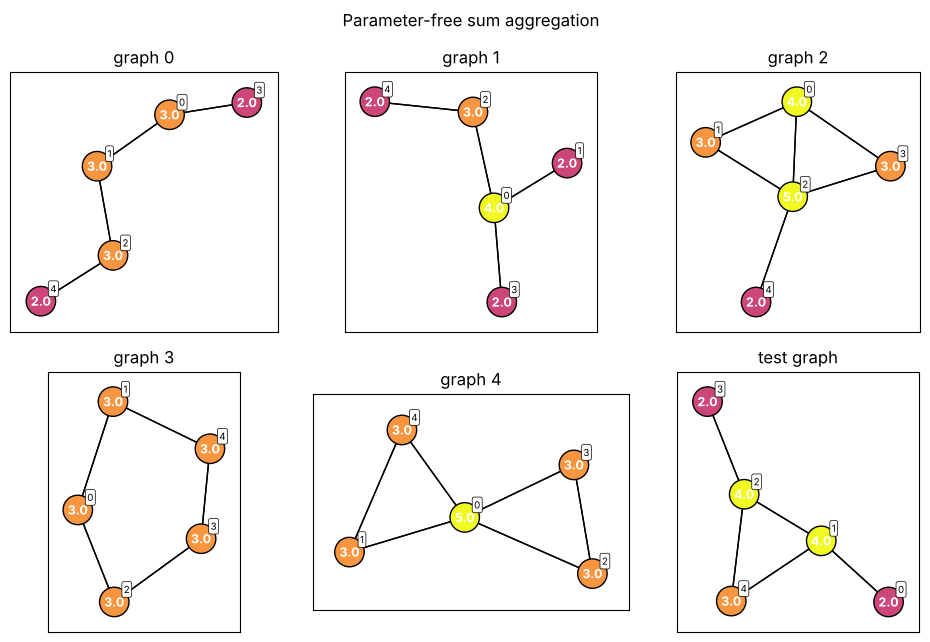

In [2]:
counting = NeighbourAggregation(aggr="add")
show([counting(g.x, g.edge_index) for g in graphs], "Parameter-free sum aggregation")

## Training the $\psi$ and $\phi\psi$ layers

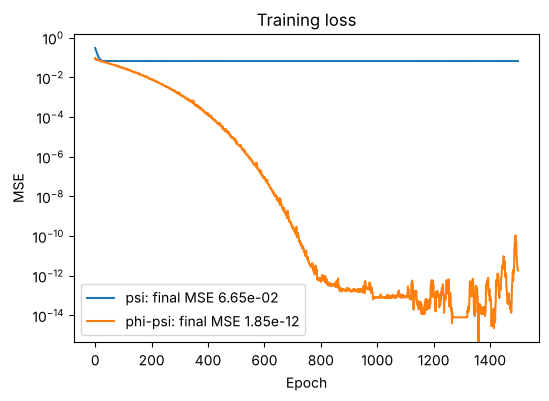

In [3]:
class NodeModel(nn.Module):
    """Wrap a message-passing layer so it takes a whole graph (or batch)."""

    def __init__(self, layer):
        super().__init__()
        self.layer = layer

    def forward(self, data):
        return self.layer(data.x, data.edge_index)


class PsiConv(MessagePassing):
    """x_i' = sum_j psi(x_j)"""

    def __init__(self, d_in=1, d_out=1):
        super().__init__(aggr="add")
        self.psi = nn.Linear(d_in, d_out)

    def forward(self, x, edge_index):
        return self.propagate(edge_index, x=x)

    def message(self, x_j):
        return self.psi(x_j)


loader = DataLoader(train_graphs, batch_size=1, shuffle=True)
models = {"psi": NodeModel(PsiConv()), "phi-psi": NodeModel(PhiPsiConv(1, 1, d_message=16))}
histories = {name: train(model, loader, epochs=1500, lr=1e-3)
             for name, model in models.items()}

fig, ax = plt.subplots(figsize=(6, 4))
for name, h in histories.items():
    ax.plot(h["train"], label=f"{name}: final MSE {h['train'][-1]:.2e}")
ax.set(xlabel="Epoch", ylabel="MSE", yscale="log", title="Training loss")
ax.legend()
plt.show()

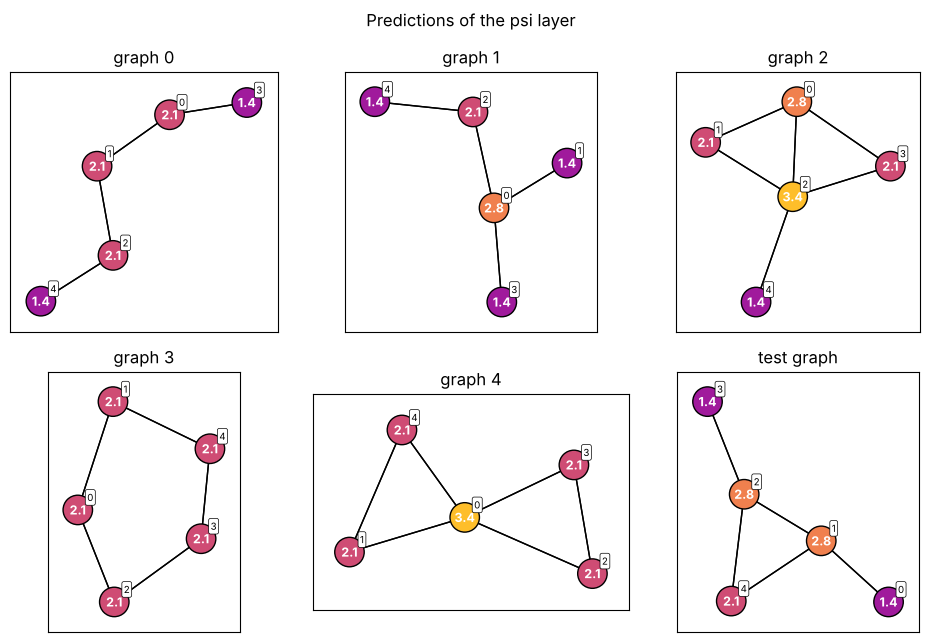

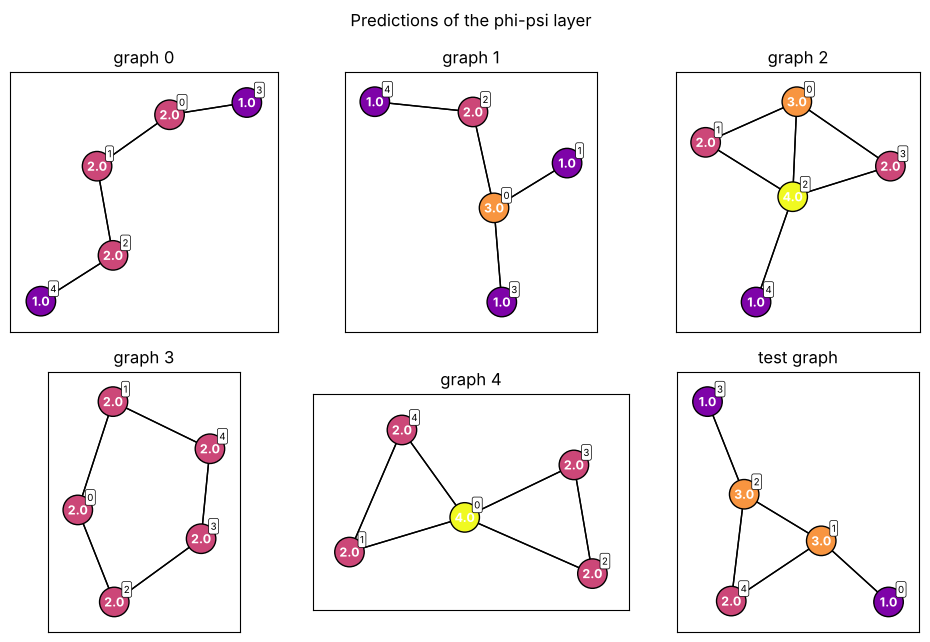

In [4]:
with torch.no_grad():
    for name, model in models.items():
        show([model(g) for g in graphs], f"Predictions of the {name} layer")

The $\psi$ layer can only multiply *degree + 1* by a constant, so it cannot
hit every target and its loss plateaus. Because $\phi$ also sees the node's
own attribute it can subtract the self-loop contribution, learning the degree
exactly – including for the unseen test graph.